# 📊 Semana 02 — Análise Visual do Benchmark de SLMs Locais

Este notebook consome os resultados reais gravados em `db/lab_experiments.db` (tabela `benchmarks`) para responder a uma pergunta prática de engenharia:
> **Qual tamanho de modelo (`1.5B`, `3B`, `7B`) e qual quantização (`Q4_K_M` vs. `Q8_0`) entregam o melhor equilíbrio entre velocidade e custo de memória no hardware local?**

---
### 📥 1. Carga e Preparação dos Dados (`SQLite` → `Pandas`)
O bloco abaixo lê os últimos 4 benchmarks, extrai o tamanho em `GB` como número (`size_gb`) e classifica cada execução em **`100% GPU`** ou **`CPU/GPU Offloading`**.

In [1]:
import sqlite3
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Permite importar settings de src/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT / "src"))
from settings import settings

sns.set_theme(style="whitegrid", palette="muted")

with sqlite3.connect(settings.lab_db_path) as conn:
    df = pd.read_sql_query(
        """
        SELECT model_name, ollama_size, ollama_processor,
               ttft_ms_avg, tps_avg, latency_p50_ms, latency_p95_ms, ram_free_mb, created_at
        FROM benchmarks
        ORDER BY id DESC
        LIMIT 4
        """,
        conn,
    )

df["size_gb"] = df["ollama_size"].str.replace(" GB", "", regex=False).astype(float)
df["is_full_gpu"] = df["ollama_processor"].str.contains("100% GPU", na=False)
df["modo_execucao"] = df["is_full_gpu"].map({True: "100% GPU", False: "CPU/GPU Offloading"})
df = df.sort_values("size_gb").reset_index(drop=True)
df[["model_name", "size_gb", "ollama_processor", "ttft_ms_avg", "tps_avg", "latency_p50_ms", "latency_p95_ms"]]

,model_name,size_gb,ollama_processor,ttft_ms_avg,tps_avg,latency_p50_ms,latency_p95_ms
0,qwen2.5:1.5b,1.1,100% GPU,245.39,85.40,1794.07,1833.89
1,qwen2.5:3b,2.1,100% GPU,342.30,48.84,2951.39,3312.96
2,qwen2.5:3b-instruct-q8_0,3.8,38%/62% CPU/GPU,1361.87,11.37,14391.57,16651.59
3,qwen2.5:7b,5.0,55%/45% CPU/GPU,4351.69,4.65,31676.01,39061.91


### 🔍 Leitura Inicial da Tabela
Já na tabela bruta fica visível a quebra em dois grupos: modelos até **`2,1 GB`** rodam inteiramente na placa de vídeo (`100% GPU`), enquanto modelos a partir de **`3,8 GB`** sofrem divisão entre `CPU` e `GPU`.

---
## Insight 1 — Fronteira de Eficiência (`Memória GB` vs. `Tokens/s`)

Este gráfico de dispersão cruza o **tamanho alocado na memória (eixo X)** com a **velocidade de geração em `tokens/s` (eixo Y)**.
* **Cor / Formato**: diferencia modelos `100% GPU` dos modelos em `CPU/GPU Offloading`.
* **Linha pontilhada vermelha (`15 tok/s`)**: corte mínimo definido na Semana 02 para que a geração seja fluida (acima da velocidade de leitura humana).

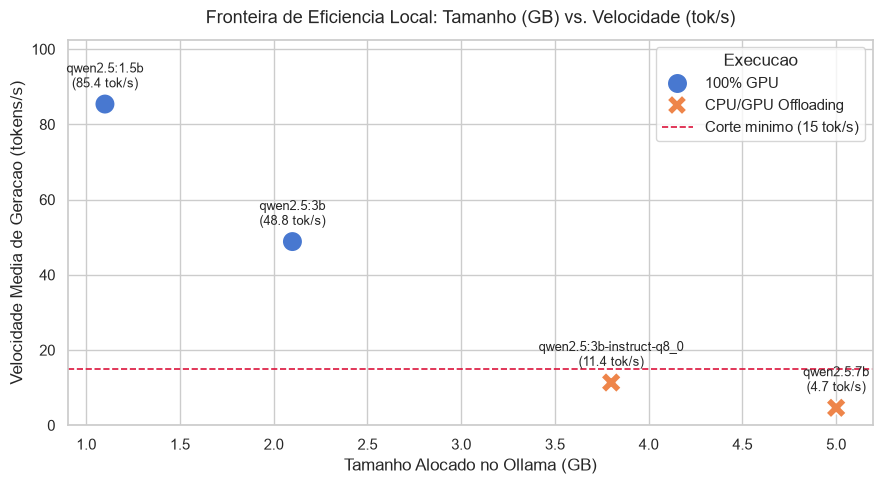

In [2]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(
    data=df,
    x="size_gb",
    y="tps_avg",
    hue="modo_execucao",
    style="modo_execucao",
    s=220,
    ax=ax,
)
ax.axhline(15, color="crimson", linestyle="--", linewidth=1.2, label="Corte minimo (15 tok/s)")

for _, row in df.iterrows():
    ax.annotate(
        f"{row['model_name']}\n({row['tps_avg']:.1f} tok/s)",
        (row["size_gb"], row["tps_avg"]),
        textcoords="offset points",
        xytext=(0, 12),
        ha="center",
        fontsize=9,
    )

ax.set_title("Fronteira de Eficiencia Local: Tamanho (GB) vs. Velocidade (tok/s)", fontsize=13, pad=12)
ax.set_xlabel("Tamanho Alocado no Ollama (GB)")
ax.set_ylabel("Velocidade Media de Geracao (tokens/s)")
ax.set_ylim(0, df["tps_avg"].max() * 1.2)
ax.legend(title="Execucao")
plt.tight_layout()
plt.show()

### 🔍 Análise — O Limite Físico do Hardware vs. Tamanho do Modelo

O gráfico deixa claro que **modelos maiores só compensam quando o hardware consegue mantê-los na `VRAM`**:

* **Na zona `100% GPU` (`1.5B` e `3B Q4_K_M`)**: Como os pesos (`1,1 GB` e `2,1 GB`) cabem inteiros na memória rápida da placa de vídeo, a leitura dos pesos por token é paralela e veloz (`85,4` e `48,8 tok/s`).
* **Ao cruzar o degrau da VRAM (`3B Q8_0` com `3,8 GB` e `7B` com `5,0 GB`)**: O Ollama precisa dividir as camadas (*Layer Offloading*) e jogar `38%` a `55%` do modelo para a `RAM` principal (processada pela `CPU`). Como a largura de banda da `RAM` é muito menor que a da `VRAM`, a velocidade despenca abaixo do corte de `15 tok/s` (`11,4` e `4,65 tok/s`).
* **Lição prática**: Não adianta escolher um modelo de `7B` parâmetros pela qualidade teórica se ele não cabe na `VRAM` e torna o fluxo lento demais para automações.

---
## Insight 2 — Estabilidade de Latência (`TTFT` vs. `p50` vs. `p95`)

Este gráfico de barras agrupadas compara três momentos da experiência de uso (em segundos) para cada modelo:
* **`TTFT` (azul)**: tempo até o 1º token aparecer na tela (*prefill* do prompt).
* **`p50` (laranja)**: mediana do tempo total — o comportamento típico em metade das chamadas.
* **`p95` (verde)**: percentil 95 — o pior caso realista (95% das chamadas terminaram até esse tempo).

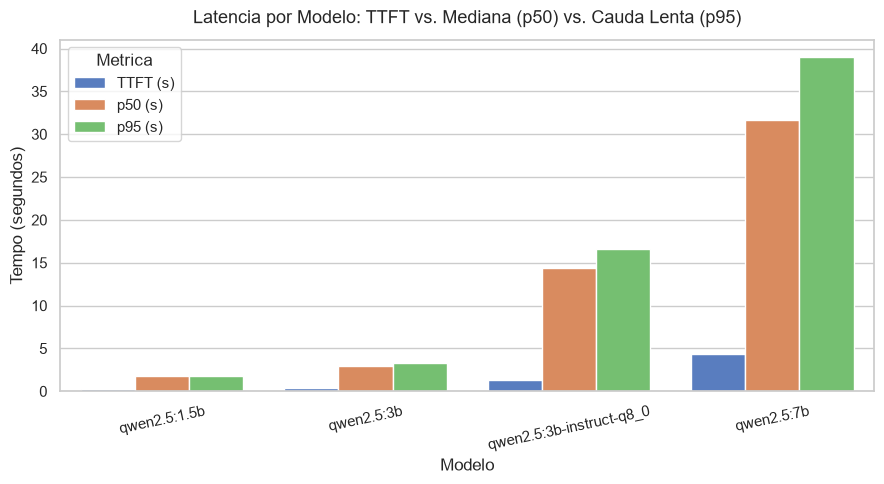

In [3]:
df_lat = df.copy()
df_lat["TTFT (s)"] = df_lat["ttft_ms_avg"] / 1000.0
df_lat["p50 (s)"] = df_lat["latency_p50_ms"] / 1000.0
df_lat["p95 (s)"] = df_lat["latency_p95_ms"] / 1000.0

melted = df_lat.melt(
    id_vars="model_name",
    value_vars=["TTFT (s)", "p50 (s)", "p95 (s)"],
    var_name="Metrica",
    value_name="Segundos",
)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=melted, x="model_name", y="Segundos", hue="Metrica", ax=ax)
ax.set_title("Latencia por Modelo: TTFT vs. Mediana (p50) vs. Cauda Lenta (p95)", fontsize=13, pad=12)
ax.set_xlabel("Modelo")
ax.set_ylabel("Tempo (segundos)")
plt.xticks(rotation=12)
plt.tight_layout()
plt.show()

### 🔍 Análise — Por que `p50` e `p95` se separam nos modelos maiores?

1. **O `TTFT` (barra azul) é relativamente baixo, mas cresce com o *offloading***: Nos modelos `100% GPU`, a resposta começa quase na hora (`0,25 s` a `0,34 s`). No `7B`, o *prefill* sobe para `4,35 s` porque metade da leitura inicial passa pela `CPU`.
2. **A discrepância entre `p50` e `p95` dispara fora da GPU**:
   * No `3B Q4_K_M` (`100% GPU`), `p50` (`2,95 s`) e `p95` (`3,31 s`) variam apenas `0,36 s` — latência **previsível**.
   * No `7B` (`55%/45% CPU/GPU`), `p50` (`31,68 s`) salta para `39,06 s` no `p95` (`+7,4 s` de diferença!).
3. **Por que isso acontece?** Na geração autorregressiva, cada token extra gerado precisa percorrer todas as camadas novamente. Quando `38%` a `55%` das camadas estão na `RAM/CPU`, qualquer prompt que exija uma resposta um pouco mais longa acumula atraso **token a token**, abrindo a cauda lenta (`p95`) e tornando o tempo de espera problemático em uso real.

---
## Insight 3 — O Custo Real do Offloading no Mesmo Modelo (`3B Q4_K_M` vs. `3B Q8_0`)

Para fazer uma comparação científica justa, este bloco **isola o mesmo modelo (`qwen2.5:3b`, 3 bilhões de parâmetros)** variando apenas a quantização (`Q4_K_M` vs. `Q8_0`). Assim eliminamos o efeito do número de parâmetros e medimos o impacto puro da precisão numérica na memória e na velocidade.

In [4]:
df_3b = df[df["model_name"].str.contains("3b")].copy()
if len(df_3b) == 2:
    q4 = df_3b[df_3b["is_full_gpu"]].iloc[0]
    q8 = df_3b[~df_3b["is_full_gpu"]].iloc[0]
    print(f"Ganho de velocidade (Q4_K_M vs Q8_0): {q4['tps_avg'] / q8['tps_avg']:.2f}x mais rapido")
    print(f"Reducao de TTFT (Q4_K_M vs Q8_0): {q8['ttft_ms_avg'] / q4['ttft_ms_avg']:.2f}x menor")
    print(f"Economia de memoria: {q8['size_gb'] - q4['size_gb']:.1f} GB ({(1 - q4['size_gb']/q8['size_gb'])*100:.1f}%)")

Ganho de velocidade (Q4_K_M vs Q8_0): 4.30x mais rapido
Reducao de TTFT (Q4_K_M vs Q8_0): 3.98x menor
Economia de memoria: 1.7 GB (44.7%)


### 🔍 Análise — Por que reduzir a precisão (`Q8_0` → `Q4_K_M`) acelerou `4,30x`?

Teoricamente, cair de `8 bits` para `4 bits` deveria economizar perto de metade da memória — e foi exatamente o que medimos (**`-1,7 GB` / `44,7%` de economia**). Porém, o ganho de velocidade não foi apenas de `2x`, e sim de **`4,30x` (`48,84` vs. `11,37 tok/s`)** e **`3,98x` menos `TTFT`**.

* **O motivo físico**: Essa economia de `1,7 GB` foi o suficiente para tirar o modelo de **`3,8 GB` (`38%/62% CPU/GPU`)** e colocá-lo inteiro em **`2,1 GB` (`100% GPU`)**. Ao eliminar o tráfego de camadas pela `RAM/CPU`, o ganho de velocidade dobrou além do esperado pela simples redução de bits!

---
## Insight 4 — Projeção Operacional para a Semana 03 (Lote de 30 Registros)

Na **Semana 03**, vamos classificar e extrair `JSON` de um *Golden Set* com **30 itens reais/simulados** (`PROB-01`, `PROB-02` e `PROB-03`). Este gráfico multiplica o `p50` medido de cada modelo por `30` para mostrar quanto tempo de relógio você esperaria por rodada de experimento.

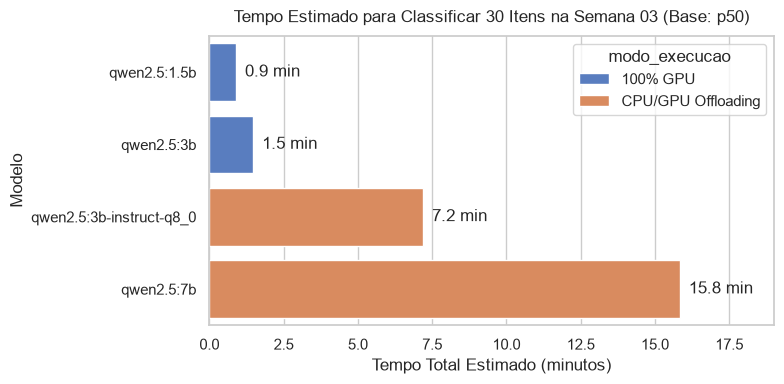

In [5]:
df["tempo_lote_30_min"] = (df["latency_p50_ms"] * 30) / 60000.0

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=df, y="model_name", x="tempo_lote_30_min", hue="modo_execucao", dodge=False, ax=ax)
for index, row in df.iterrows():
    ax.text(row["tempo_lote_30_min"] + 0.3, index, f"{row['tempo_lote_30_min']:.1f} min", va="center")

ax.set_title("Tempo Estimado para Classificar 30 Itens na Semana 03 (Base: p50)", fontsize=12, pad=10)
ax.set_xlabel("Tempo Total Estimado (minutos)")
ax.set_ylabel("Modelo")
ax.set_xlim(0, df["tempo_lote_30_min"].max() * 1.2)
plt.tight_layout()
plt.show()

### 🔍 Análise — Impacto Prático no Fluxo de Trabalho

* **Por que `1,5 min` vs `15,8 min` muda o projeto?** Em experimentos de engenharia de prompt e `JSON Schema`, é comum rodar `3` ou `4` rodadas de ajuste no mesmo dia. Com `qwen2.5:7b` (`15,8 min` por lote), `4` testes consumiriam **mais de 1 hora** só olhando para o terminal; já com `qwen2.5:3b` (`1,5 min`) ou `1.5b` (`0,9 min`), você itera em poucos minutos.

---
### ✅ Conclusão Geral para a Semana 03

* **SLM Padrão de Trabalho (`qwen2.5:3b` em `Q4_K_M`)**: `2,1 GB`, `100% GPU`, `48,8 tok/s` e `~1,5 min` para processar 30 demandas.
* **SLM Ultra-Rápido (`qwen2.5:1.5b` em `Q4_K_M`)**: `1,1 GB`, `100% GPU`, `85,4 tok/s` e `~0,9 min` para 30 demandas — ideal para testar se um modelo ainda menor já dá conta de gerar `JSON Schema` válido na Semana 03.